**24ADI204- Data Science and Visualization**

**DATA VIZ HACK A BIT (2026-2027)**

Problem Statement:
**Air Quality Analysis and Pollution Prediction**

Domain: **Environment, Climate and Public Health**

**SDG Aligned:**

SDG 3 – Good Health and Well-being


SDG 11 – Sustainable Cities and Communities


SDG 13 – Climate Action

Dataset Source: https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india

Import Libraries

In [130]:
import pandas as pd
import numpy as np

Loading the Dataset:

In [131]:
df = pd.read_csv("/content/city_day.csv")

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

Dataset loaded successfully!
Rows and Columns: (29531, 16)


Initial Records:

In [132]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


Ending Records:

In [133]:
df.tail()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


Inspecting Dataset Structure:

In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


Feature Types:

In [135]:
print("Feature Types")

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

Feature Types

Numerical Features:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']

Categorical Features:
['City', 'Date', 'AQI_Bucket']


Missing Value Observation:

In [136]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


Duplicate Records Observation:

In [137]:
df.duplicated().sum()

np.int64(0)

Time Period of Dataset Recorded:

In [138]:
print("Earliest Date:", df["Date"].min())
print("Latest Date:", df["Date"].max())

Earliest Date: 2015-01-01
Latest Date: 2020-07-01


Cities Covered in the Dataset:

In [139]:
print("Cities Covered in the Dataset:")
cities = sorted(df["City"].dropna().unique())
for city in cities:
    print(city)
print("\nTotal Number of Cities:", len(cities))

Cities Covered in the Dataset:
Ahmedabad
Aizawl
Amaravati
Amritsar
Bengaluru
Bhopal
Brajrajnagar
Chandigarh
Chennai
Coimbatore
Delhi
Ernakulam
Gurugram
Guwahati
Hyderabad
Jaipur
Jorapokhar
Kochi
Kolkata
Lucknow
Mumbai
Patna
Shillong
Talcher
Thiruvananthapuram
Visakhapatnam

Total Number of Cities: 26


AQI Category Count:

In [140]:
print("AQI Categories Present in the Dataset:")
print(df["AQI_Bucket"].value_counts(dropna=False))

AQI Categories Present in the Dataset:
AQI_Bucket
Moderate        8829
Satisfactory    8224
NaN             4681
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64


Data Quality Summary:

In [141]:
print("Data Quality Summary")
print("-" * 30)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Data Quality Summary
------------------------------
Total Rows: 29531
Total Columns: 16
Total Missing Values: 88488
Duplicate Rows: 0


First Impression Report:

In [142]:
print("First Impression Report")
print("-" * 40)

print("1. The dataset contains", df.shape[0], "records and", df.shape[1], "features.")
print("2. The dataset contains air quality measurements from", df["City"].nunique(), "cities.")
print("3. Missing values are present in several pollutant and AQI-related columns.")
print("4. No duplicate records were identified.")
print("5. The dataset contains numerical pollutant measurements along with City, Date and AQI category information.")
print("6. Further cleaning is required before performing detailed analysis.")

First Impression Report
----------------------------------------
1. The dataset contains 29531 records and 16 features.
2. The dataset contains air quality measurements from 26 cities.
3. Missing values are present in several pollutant and AQI-related columns.
4. No duplicate records were identified.
5. The dataset contains numerical pollutant measurements along with City, Date and AQI category information.
6. Further cleaning is required before performing detailed analysis.


**Week-3 The Cleaning Sprint**

1. Create a copy of Raw Dataset

In [143]:
df_clean = df.copy()

print("Working copy created successfully!")
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Working copy created successfully!
Original Dataset Shape: (29531, 16)
Working Dataset Shape: (29531, 16)


2. Initial Data Quality Report:

In [144]:
print("Initial Data Quality Report")
print("-" * 40)

print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

Initial Data Quality Report
----------------------------------------
Total Rows: 29531
Total Columns: 16
Total Missing Values: 88488
Total Duplicate Rows: 0


3. Missing Value Analysis:

In [145]:
print("Missing Value Analysis")
print("-" * 50)

missing_count = df_clean.isnull().sum()
missing_percentage = (missing_count / len(df_clean)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

missing_report = missing_report[missing_report["Missing Values"] > 0]
missing_report = missing_report.sort_values("Missing Values", ascending=False)

print(missing_report.to_string())

Missing Value Analysis
--------------------------------------------------
            Missing Values  Missing Percentage
Xylene               18109               61.32
PM10                 11140               37.72
NH3                  10328               34.97
Toluene               8041               27.23
Benzene               5623               19.04
AQI                   4681               15.85
AQI_Bucket            4681               15.85
PM2.5                 4598               15.57
NOx                   4185               14.17
O3                    4022               13.62
SO2                   3854               13.05
NO2                   3585               12.14
NO                    3582               12.13
CO                    2059                6.97


4.Missing Values by City

In [146]:
print("Missing Values by City")
print("-" * 50)

missing_by_city = df_clean.groupby("City").apply(
    lambda x: x.isnull().sum().sum(),
    include_groups=False
).sort_values(ascending=False)

print(missing_by_city.to_string())

Missing Values by City
--------------------------------------------------
City
Mumbai                14201
Ahmedabad             10784
Jorapokhar             8603
Gurugram               6843
Patna                  6214
Lucknow                6082
Chennai                5301
Brajrajnagar           4281
Talcher                4014
Thiruvananthapuram     3805
Bengaluru              3452
Visakhapatnam          2382
Amritsar               1828
Hyderabad              1583
Jaipur                 1416
Amaravati              1190
Delhi                  1087
Shillong               1073
Guwahati               1033
Bhopal                  970
Kolkata                 816
Coimbatore              693
Kochi                   356
Ernakulam               275
Aizawl                  159
Chandigarh               47


5. Missing Value Percentage by City

In [147]:
print("Missing Value Percentage by City")
print("-" * 50)

city_missing_percentage = df_clean.groupby("City").apply(
    lambda x: x.isnull().sum().sum() / x.size * 100,
    include_groups=False
).sort_values(ascending=False)

print(city_missing_percentage.round(2).to_string())

Missing Value Percentage by City
--------------------------------------------------
City
Jorapokhar            49.06
Mumbai                47.12
Ahmedabad             35.79
Brajrajnagar          30.43
Talcher               28.93
Gurugram              27.17
Shillong              23.08
Thiruvananthapuram    22.81
Bhopal                22.38
Patna                 22.30
Lucknow               20.18
Chennai               17.59
Kochi                 14.65
Guwahati              13.72
Coimbatore            11.97
Bengaluru             11.46
Ernakulam             11.32
Visakhapatnam         10.86
Amritsar               9.98
Aizawl                 9.38
Jaipur                 8.47
Amaravati              8.34
Kolkata                6.68
Hyderabad              5.26
Delhi                  3.61
Chandigarh             1.03


6.Missing Values in AQI and AQI Category

In [148]:
print("Missing Values in AQI and AQI Category")
print("-" * 50)

print("Missing AQI Values:", df_clean["AQI"].isnull().sum())
print("Missing AQI Category Values:", df_clean["AQI_Bucket"].isnull().sum())

Missing Values in AQI and AQI Category
--------------------------------------------------
Missing AQI Values: 4681
Missing AQI Category Values: 4681


7. Missing Value Treatment Decision

In [149]:
print("Missing Value Treatment Decision")
print("-" * 50)

for column in missing_percentage[missing_percentage > 0].index:
    percentage = missing_percentage[column]

    if percentage < 5:
        decision = "Low missingness"
    elif percentage < 30:
        decision = "Moderate missingness"
    else:
        decision = "High missingness"

    print(f"{column}: {percentage:.2f}% - {decision}")

Missing Value Treatment Decision
--------------------------------------------------
PM2.5: 15.57% - Moderate missingness
PM10: 37.72% - High missingness
NO: 12.13% - Moderate missingness
NO2: 12.14% - Moderate missingness
NOx: 14.17% - Moderate missingness
NH3: 34.97% - High missingness
CO: 6.97% - Moderate missingness
SO2: 13.05% - Moderate missingness
O3: 13.62% - Moderate missingness
Benzene: 19.04% - Moderate missingness
Toluene: 27.23% - Moderate missingness
Xylene: 61.32% - High missingness
AQI: 15.85% - Moderate missingness
AQI_Bucket: 15.85% - Moderate missingness


8. Apply missing-value treatment

In [150]:
print("Applying Missing Value Treatment")
print("-" * 50)

numerical_columns = df_clean.select_dtypes(include=np.number).columns

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

df_clean["AQI_Bucket"] = df_clean["AQI_Bucket"].fillna(
    df_clean["AQI_Bucket"].mode()[0]
)

print("Missing value treatment completed.")

Applying Missing Value Treatment
--------------------------------------------------
Missing value treatment completed.


9. Verify Missing Values

In [151]:
print("Missing Values After Treatment")
print("-" * 50)

remaining_missing = df_clean.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

if remaining_missing.empty:
    print("No missing values remain in the dataset.")
else:
    print(remaining_missing.to_string())

Missing Values After Treatment
--------------------------------------------------
No missing values remain in the dataset.


10. Outlier Detection Using Boxplots

Outlier Detection Using Boxplots


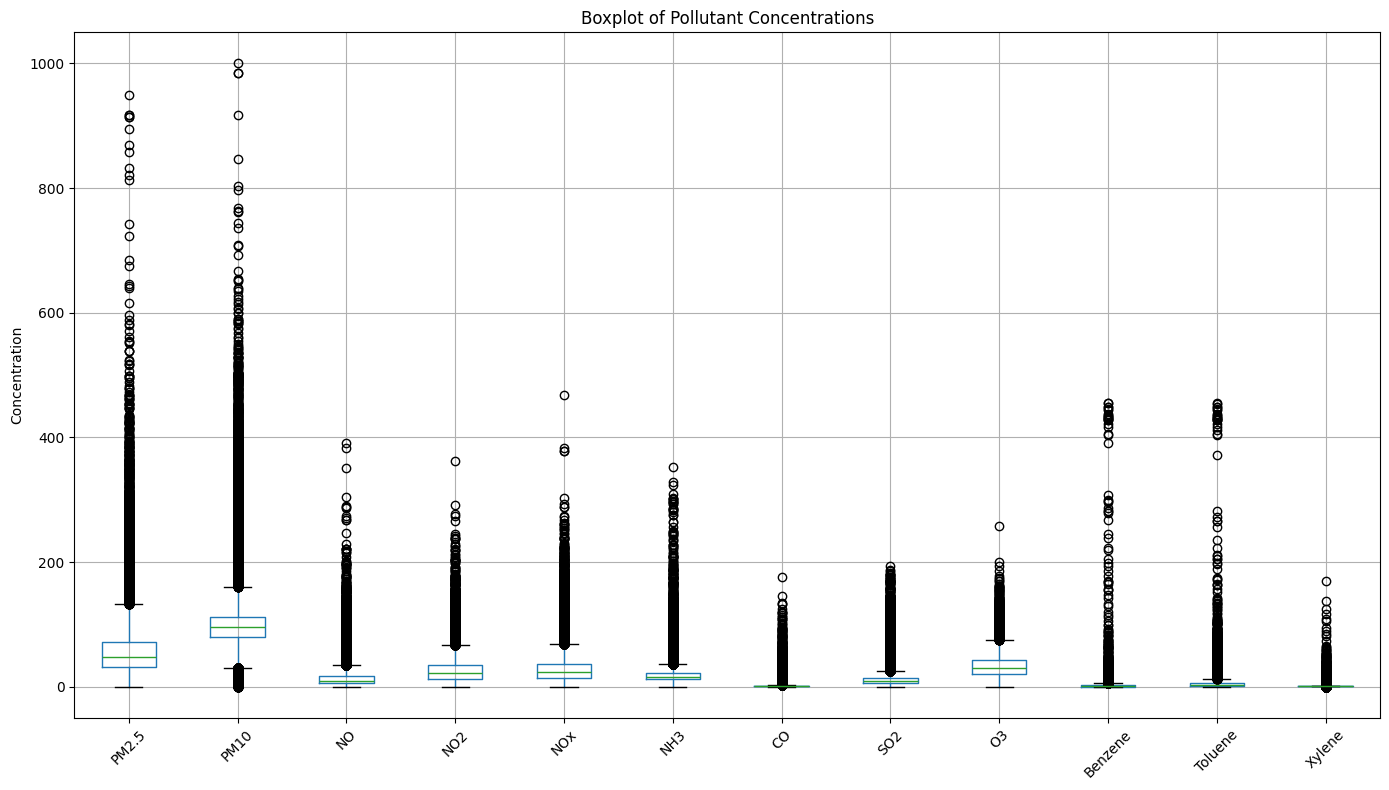

In [152]:
import matplotlib.pyplot as plt

print("Outlier Detection Using Boxplots")

numerical_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

plt.figure(figsize=(14, 8))
df_clean[numerical_pollutants].boxplot()

plt.title("Boxplot of Pollutant Concentrations")
plt.ylabel("Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

11. Z-Score Outlier Detection

In [153]:
from scipy.stats import zscore

print("Outlier Detection Using Z-Score")
print("-" * 50)

z_scores = df_clean[numerical_pollutants].apply(zscore)

outlier_counts = (abs(z_scores) > 3).sum()

print(outlier_counts[outlier_counts > 0].sort_values(ascending=False).to_string())

Outlier Detection Using Z-Score
--------------------------------------------------
PM10       740
NO         700
NOx        680
SO2        651
PM2.5      628
CO         565
NO2        536
NH3        513
Xylene     467
O3         447
Toluene    331
Benzene    110


12. Outlier Summary

In [154]:
print("Outlier Detection Summary")
print("-" * 50)

print("Boxplot Method: Potential outliers identified visually.")
print("Z-Score Method: Values with |Z-score| > 3 were identified as potential outliers.")
print("Treatment Decision: Potential outliers will be retained because extreme pollution values may represent genuine environmental observations.")

Outlier Detection Summary
--------------------------------------------------
Boxplot Method: Potential outliers identified visually.
Z-Score Method: Values with |Z-score| > 3 were identified as potential outliers.
Treatment Decision: Potential outliers will be retained because extreme pollution values may represent genuine environmental observations.


13. Final Data Quality Check

In [155]:
print("Final Data Quality Check")
print("-" * 50)

print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])
print("Remaining Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

Final Data Quality Check
--------------------------------------------------
Total Rows: 29531
Total Columns: 16
Remaining Missing Values: 0
Duplicate Rows: 0


14. Save the cleaned Dataset

In [156]:
df_clean.to_csv("city_day_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("File name: city_day_cleaned.csv")

Cleaned dataset saved successfully!
File name: city_day_cleaned.csv


**Week-4 EDA Deep Dive**

Cleaned Dataset Shape:

In [157]:
print("Cleaned Dataset Shape:", df_clean.shape)

Cleaned Dataset Shape: (29531, 16)


Summary Statistics:

In [158]:
summary_stats = df_clean.describe().T

print(summary_stats.to_string())

           count        mean         std    min     25%     50%      75%      max
PM2.5    29531.0   64.510857   59.807551   0.04  32.150   48.57   72.450   949.99
PM10     29531.0  109.659366   72.324020   0.01  79.315   95.68  111.880  1000.00
NO       29531.0   16.642601   21.506064   0.02   6.210    9.89   17.570   390.68
NO2      29531.0   27.726576   23.050531   0.01  12.980   21.69   34.665   362.21
NOx      29531.0   31.063568   29.477748   0.00  14.670   23.52   36.015   467.63
NH3      29531.0   20.813789   21.028862   0.01  12.040   15.85   21.755   352.89
CO       29531.0    2.153872    6.724660   0.00   0.540    0.89    1.380   175.81
SO2      29531.0   13.830897   17.005647   0.01   6.090    9.16   13.810   193.86
O3       29531.0   33.994121   20.202304   0.01  20.740   30.84   42.730   257.73
Benzene  29531.0    2.859874   14.252822   0.00   0.240    1.07    2.420   455.03
Toluene  29531.0    7.140485   17.224737   0.00   1.280    2.97    6.020   454.85
Xylene   29531.0

**Univariate Visualizations:**

1. AQI Distribution (Histogram):

U1. AQI Distribution


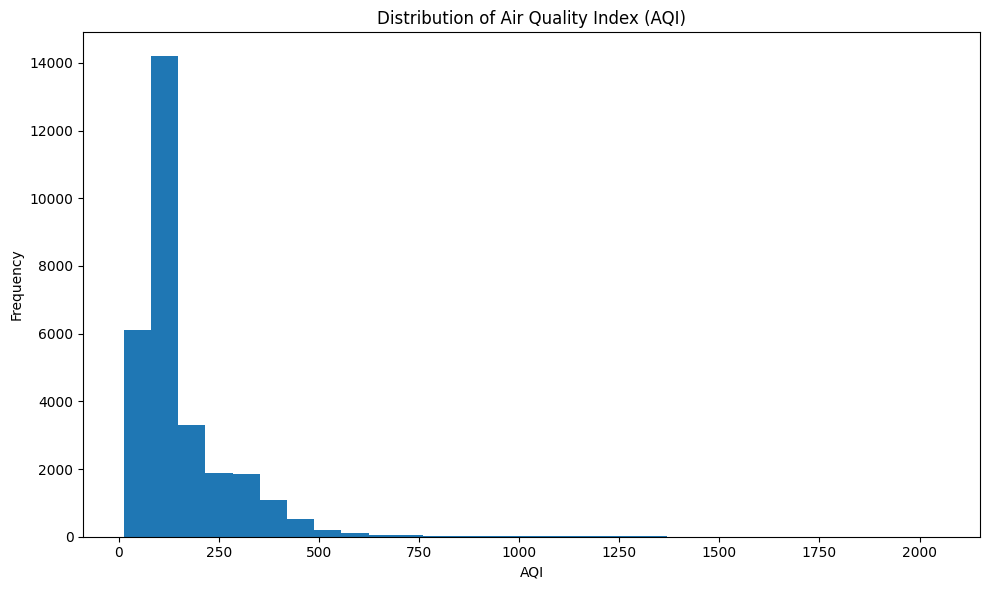

In [159]:
import matplotlib.pyplot as plt

print("U1. AQI Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["AQI"], bins=30)

plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.title("Distribution of Air Quality Index (AQI)")

plt.tight_layout()
plt.show()

2. AQI Boxplot:

U2. AQI Boxplot


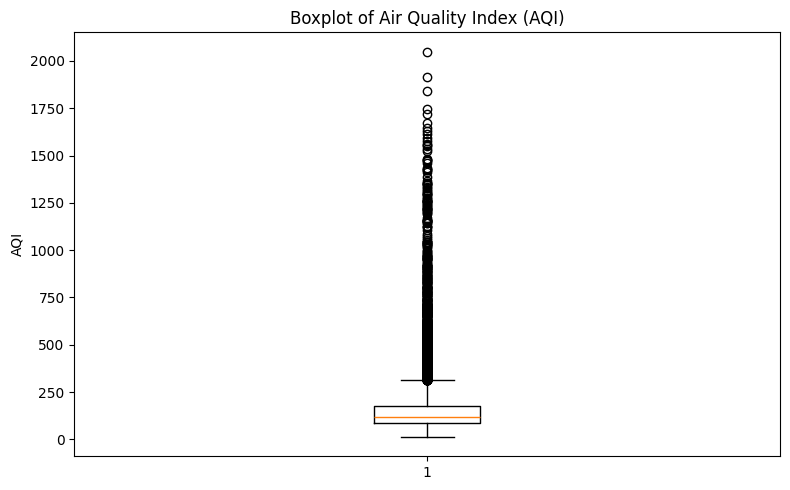

In [160]:
print("U2. AQI Boxplot")

plt.figure(figsize=(8, 5))

plt.boxplot(df_clean["AQI"])

plt.ylabel("AQI")
plt.title("Boxplot of Air Quality Index (AQI)")

plt.tight_layout()
plt.show()

3. AQI Category Distribution:

U3. AQI Category Distribution


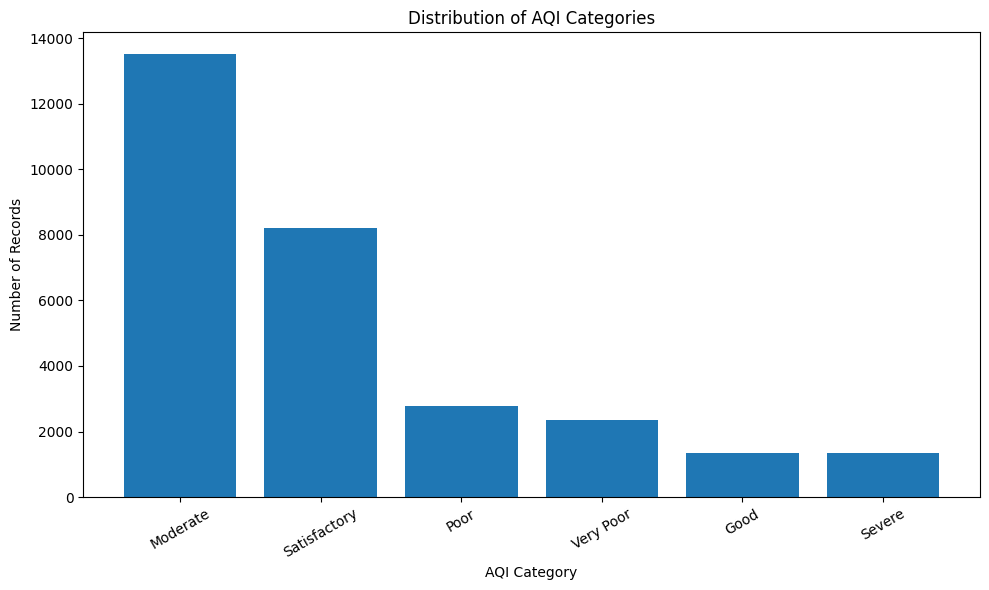

In [161]:
print("U3. AQI Category Distribution")

category_counts = df_clean["AQI_Bucket"].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.title("Distribution of AQI Categories")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

4. PM2.5 Distribution:

U4. PM2.5 Distribution


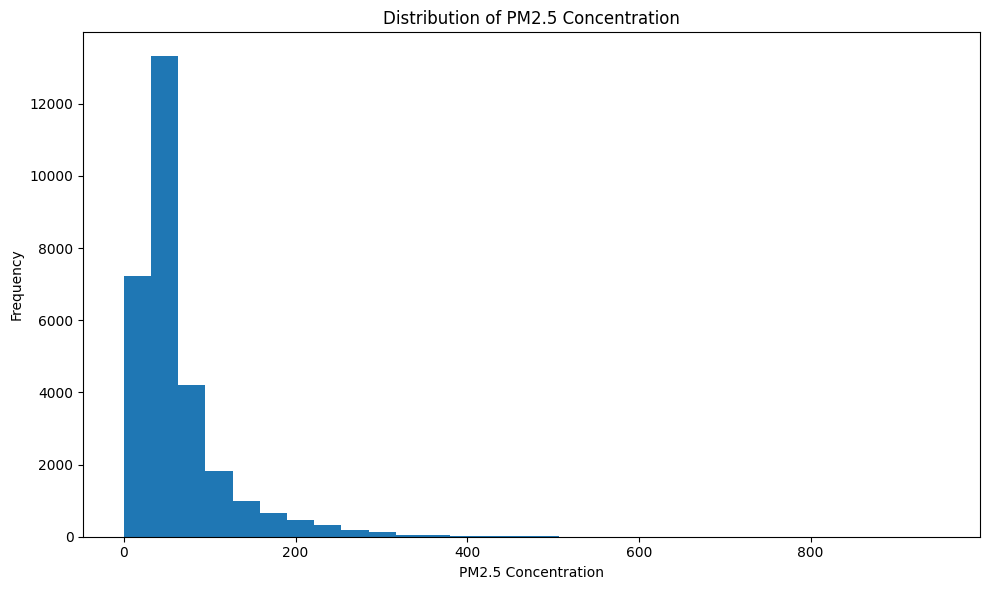

In [162]:
print("U4. PM2.5 Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["PM2.5"], bins=30)

plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.title("Distribution of PM2.5 Concentration")

plt.tight_layout()
plt.show()

5. PM10 Distribution:

U5. PM10 Distribution


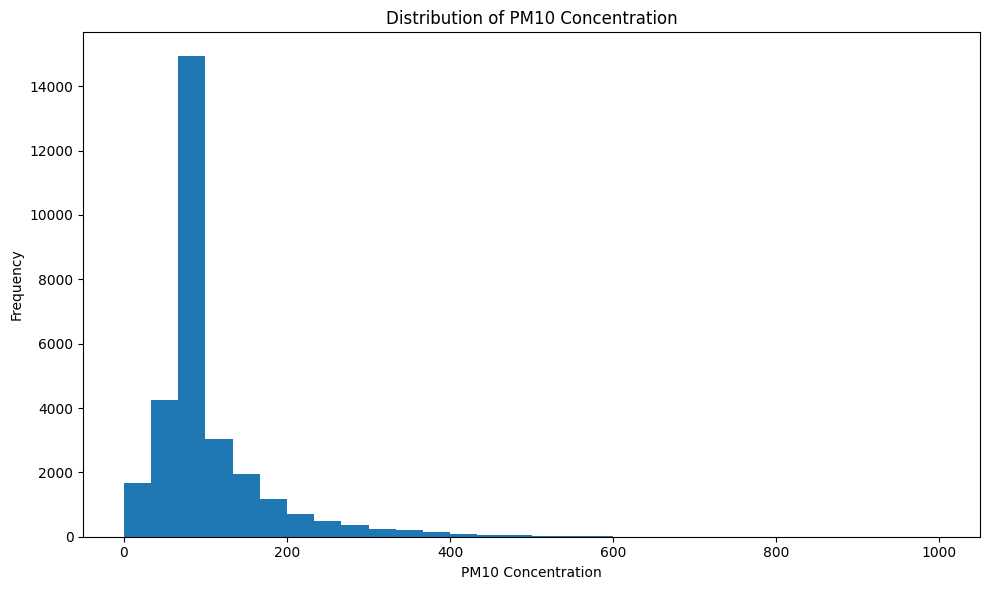

In [163]:
print("U5. PM10 Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["PM10"], bins=30)

plt.xlabel("PM10 Concentration")
plt.ylabel("Frequency")
plt.title("Distribution of PM10 Concentration")

plt.tight_layout()
plt.show()

6. Major Pollutants Boxplot:

U6. Major Pollutants Boxplot


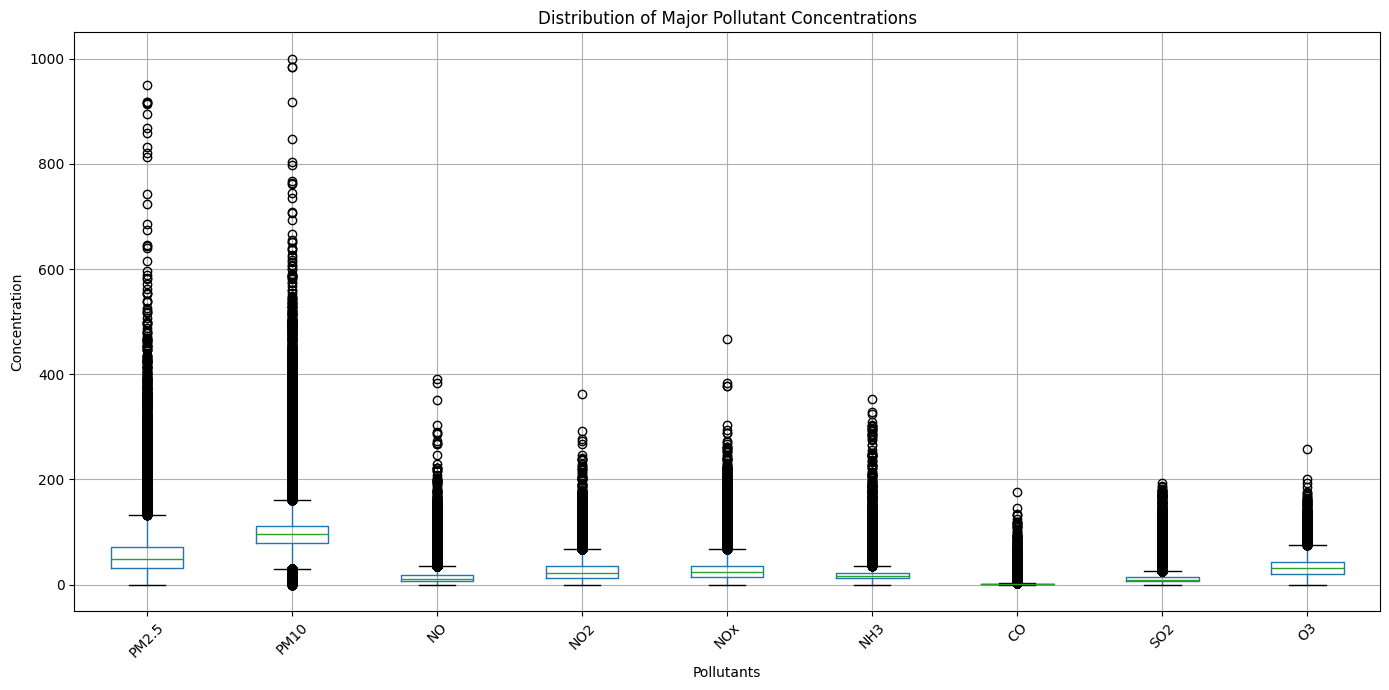

In [164]:
print("U6. Major Pollutants Boxplot")

major_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3"
]

plt.figure(figsize=(14, 7))

df_clean[major_pollutants].boxplot()

plt.xlabel("Pollutants")
plt.ylabel("Concentration")
plt.title("Distribution of Major Pollutant Concentrations")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

7. City-wise AQI Distribution:

U8. City-wise AQI Distribution


<Figure size 1600x800 with 0 Axes>

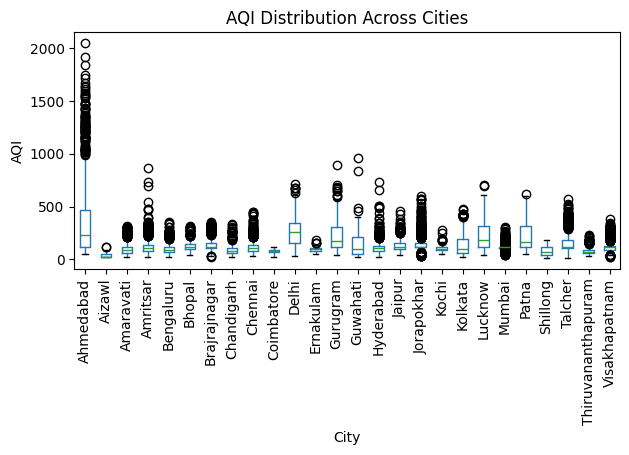

In [165]:
print("U8. City-wise AQI Distribution")

plt.figure(figsize=(16, 8))

df_clean.boxplot(
    column="AQI",
    by="City",
    grid=False
)

plt.xlabel("City")
plt.ylabel("AQI")
plt.title("AQI Distribution Across Cities")
plt.suptitle("")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Bivariate Visualizations:**

1. PM2.5 vs AQI — Scatter Plot:

B1. PM2.5 vs AQI


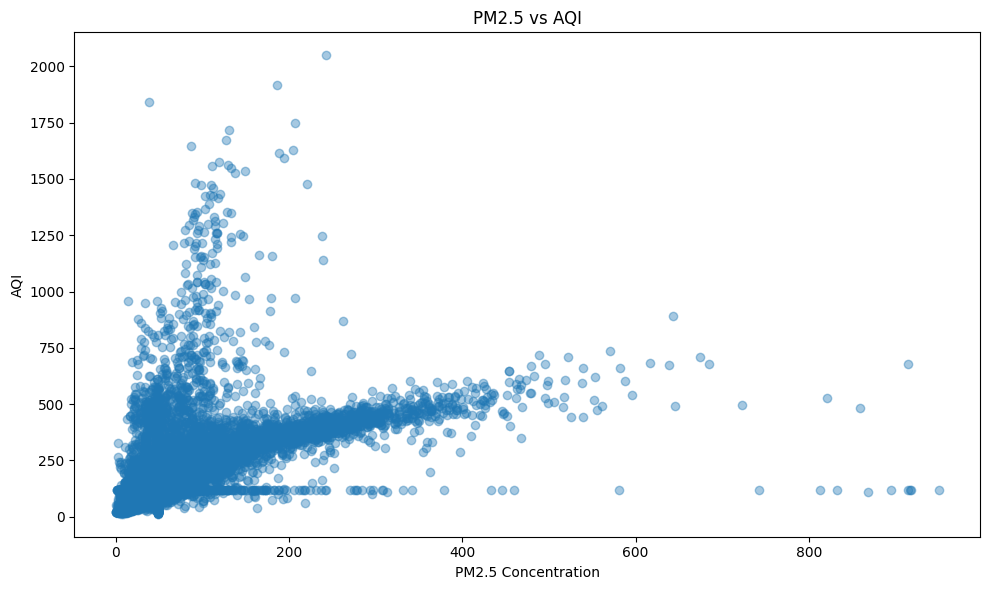

In [166]:
print("B1. PM2.5 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["PM2.5"], df_clean["AQI"], alpha=0.4)

plt.xlabel("PM2.5 Concentration")
plt.ylabel("AQI")
plt.title("PM2.5 vs AQI")

plt.tight_layout()
plt.show()

2. PM10 vs AQI — Scatter Plot:

B2. PM10 vs AQI


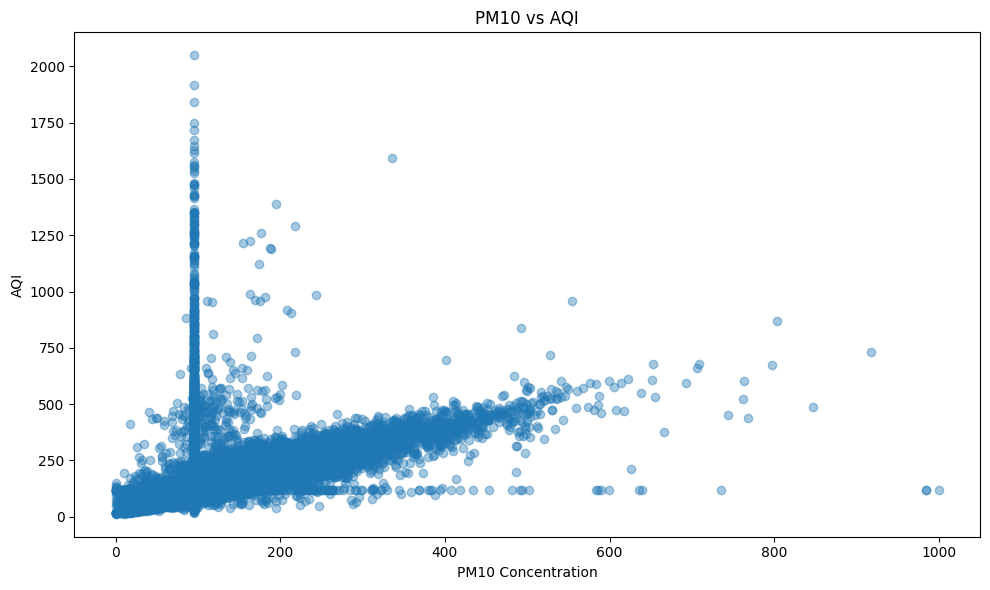

In [167]:
print("B2. PM10 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["PM10"], df_clean["AQI"], alpha=0.4)

plt.xlabel("PM10 Concentration")
plt.ylabel("AQI")
plt.title("PM10 vs AQI")

plt.tight_layout()
plt.show()

3. NO2 vs AQI — Scatter Plot:

B3. NO2 vs AQI


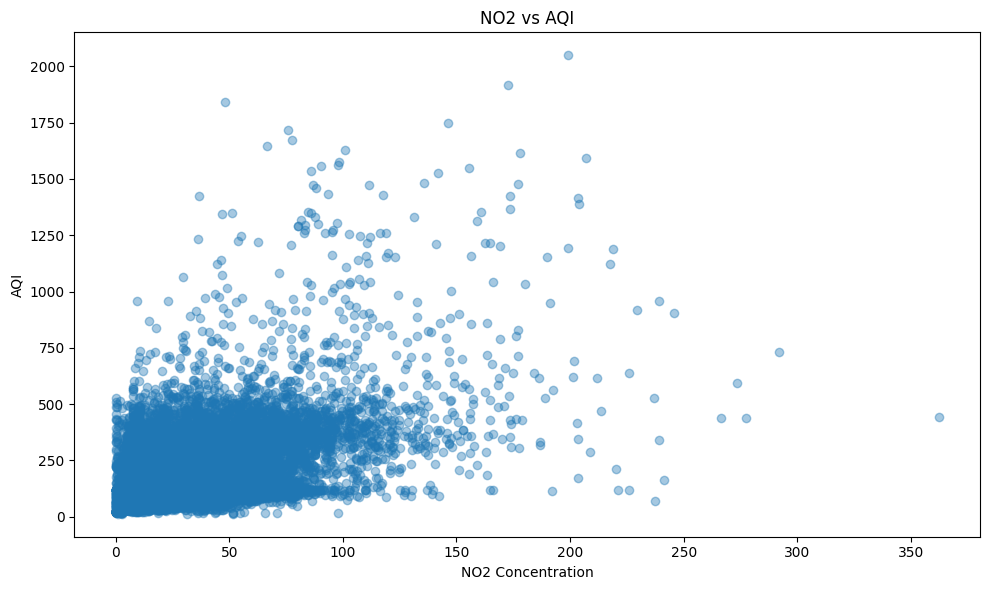

In [168]:
print("B3. NO2 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["NO2"], df_clean["AQI"], alpha=0.4)

plt.xlabel("NO2 Concentration")
plt.ylabel("AQI")
plt.title("NO2 vs AQI")

plt.tight_layout()
plt.show()

4. CO vs AQI — Scatter Plot:

B4. CO vs AQI


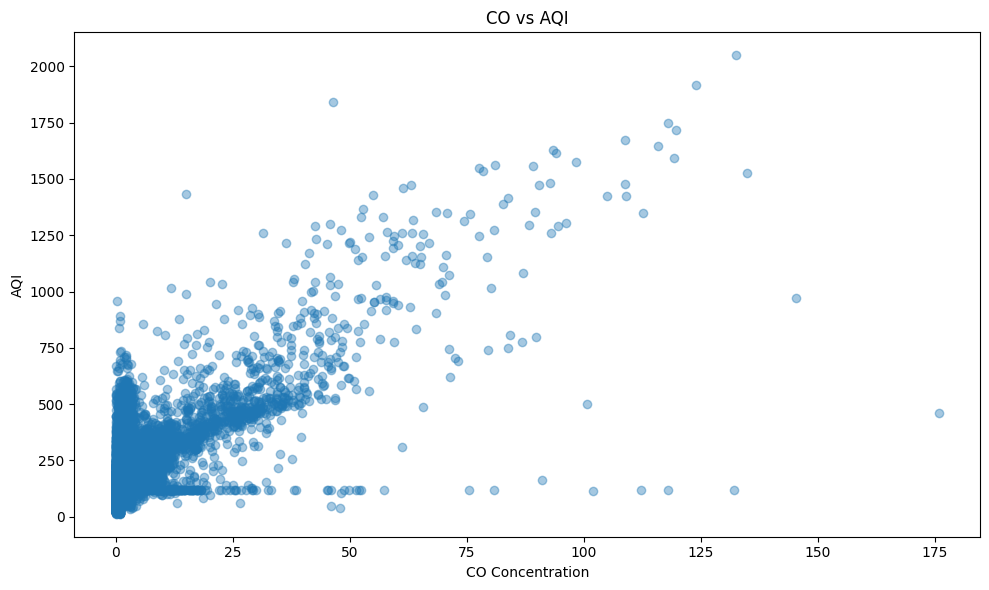

In [169]:
print("B4. CO vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["CO"], df_clean["AQI"], alpha=0.4)

plt.xlabel("CO Concentration")
plt.ylabel("AQI")
plt.title("CO vs AQI")

plt.tight_layout()
plt.show()

5. SO2 vs AQI — Scatter Plot:

B5. SO2 vs AQI


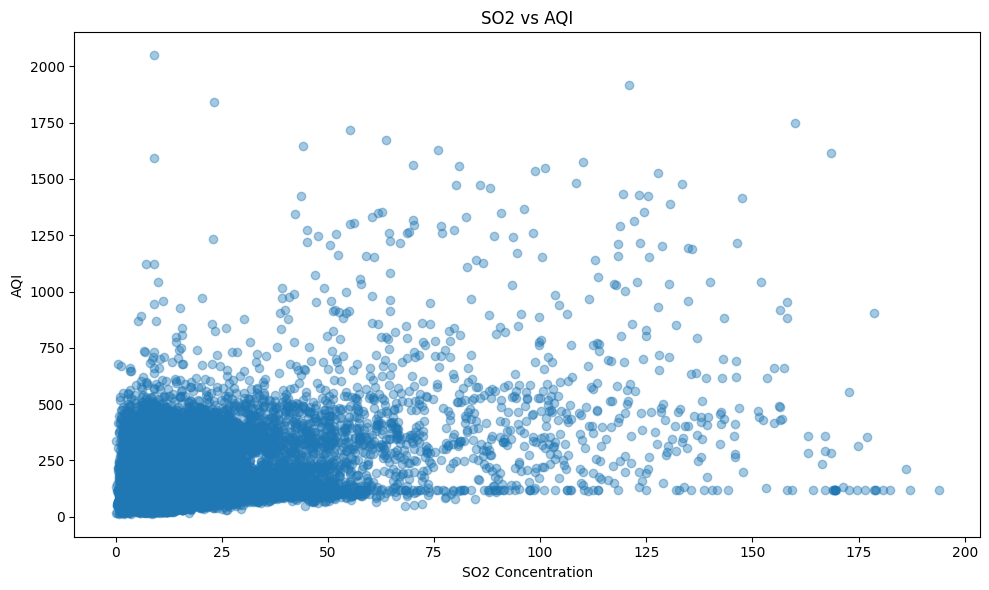

In [170]:
print("B5. SO2 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["SO2"], df_clean["AQI"], alpha=0.4)

plt.xlabel("SO2 Concentration")
plt.ylabel("AQI")
plt.title("SO2 vs AQI")

plt.tight_layout()
plt.show()

6. City vs Average AQI — Bar Chart:

B6. City vs Average AQI


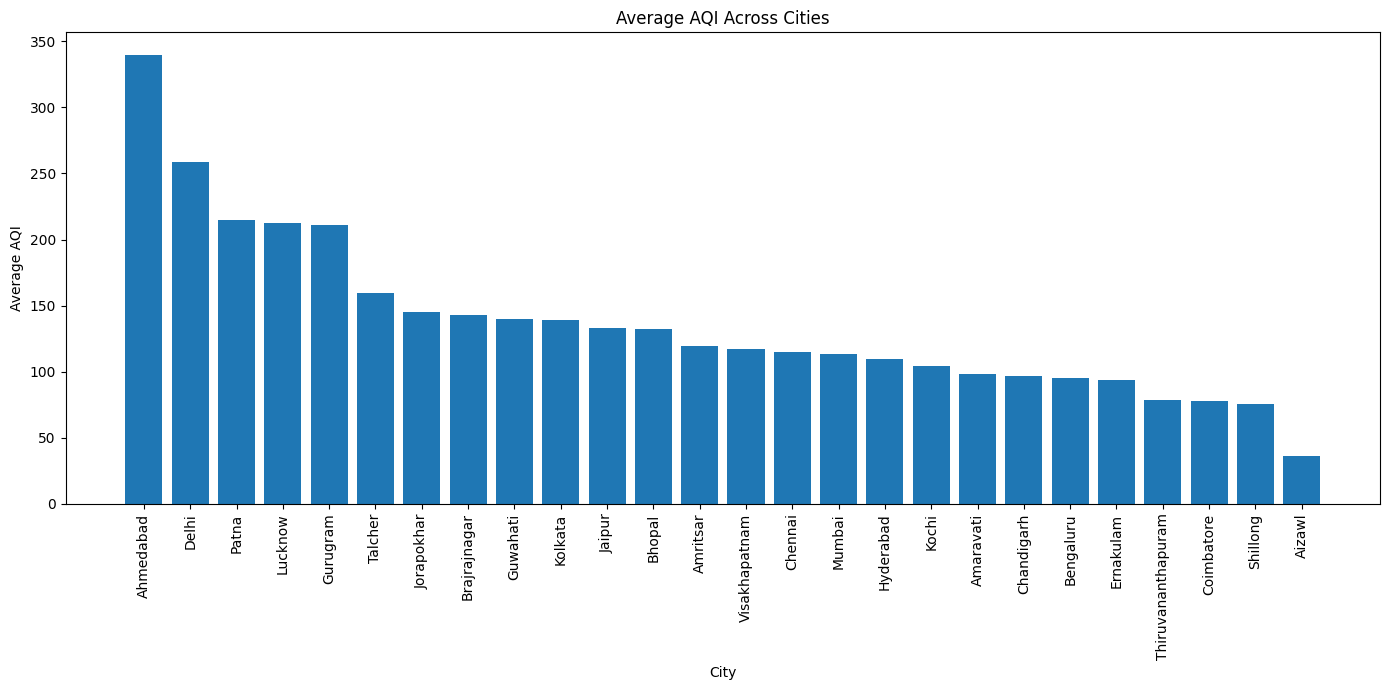

In [171]:
print("B6. City vs Average AQI")

city_aqi = (
    df_clean.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))

plt.bar(city_aqi.index, city_aqi.values)

plt.xlabel("City")
plt.ylabel("Average AQI")
plt.title("Average AQI Across Cities")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

7. AQI Category vs PM2.5 — Boxplot:

B7. AQI Category vs PM2.5


/tmp/ipykernel_2084/484771573.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=categories)


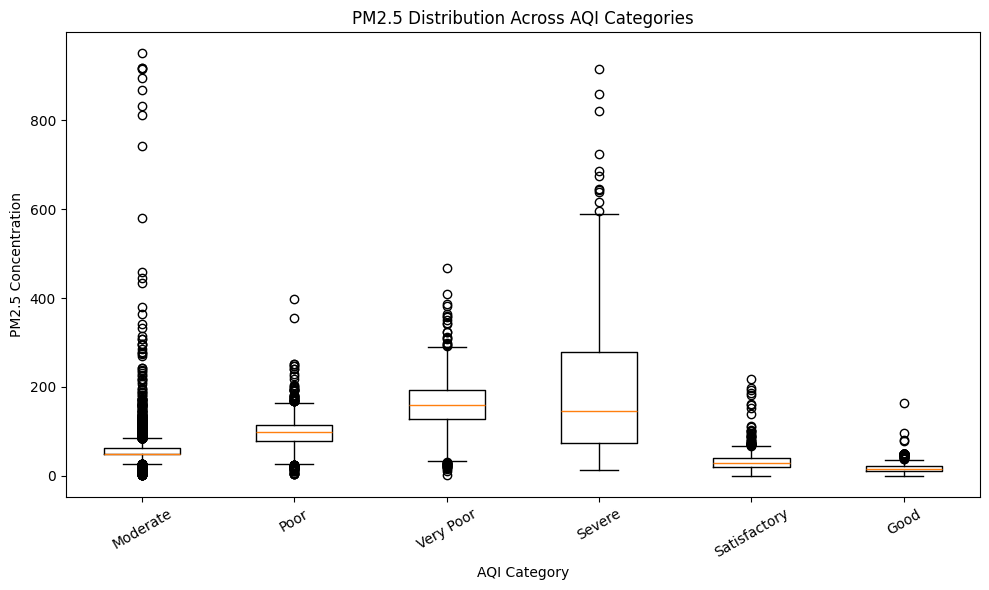

In [172]:
print("B7. AQI Category vs PM2.5")

categories = df_clean["AQI_Bucket"].unique()

data = [
    df_clean[df_clean["AQI_Bucket"] == category]["PM2.5"]
    for category in categories
]

plt.figure(figsize=(10, 6))

plt.boxplot(data, labels=categories)

plt.xlabel("AQI Category")
plt.ylabel("PM2.5 Concentration")
plt.title("PM2.5 Distribution Across AQI Categories")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Week 4 – Conclusion

The Exploratory Data Analysis (EDA) provided a clear understanding of the Air Quality Index (AQI) and pollutant characteristics in the cleaned dataset. Univariate analysis was used to study the distribution and variation of AQI and major pollutants, while bivariate analysis was used to examine relationships between pollutants and AQI and compare AQI levels across cities.

The analysis revealed noticeable variation in air quality and pollutant concentrations across the dataset. These findings provide useful insights into the pollution patterns and form the basis for further analysis and interpretation of the air quality data.